# Static Training Run Energy Simulator
Predict cumulative energy consumption over wall time for static TP/PP strategies using calibration data from `profile_strategies.py`.


## Configuration


In [571]:
STRATEGIES = [
    {'tp': 1, 'pp': 1, 'power_w': 802, 'step_time_s': 0.1875,
     'warmup_wall_s': 10.1, 'warmup_iters': 37, 'save_s': 11.00},
    {'tp': 4, 'pp': 1, 'power_w': 598.0, 'step_time_s': 0.8163,
     'warmup_wall_s': 18.9, 'warmup_iters': 21, 'save_s':  7.82},
    {'tp': 2, 'pp': 1, 'power_w': 612, 'step_time_s': 0.4158,
     'warmup_wall_s': 10.6, 'warmup_iters': 21, 'save_s':  8.80},
]

N_GPUS = 4
FRESH_BUILD_S = 0.23
IDLE_POWER_PER_GPU_W = 50.0

GLOBAL_BATCH_SIZE = 16
SEQ_LENGTH        = 1024
CONTAINER_STARTUP_S = 35.0

N_ITERS      = 200
TOTAL_TOKENS = N_ITERS * GLOBAL_BATCH_SIZE * SEQ_LENGTH

RESHARD_TIME_S = 13.68
FIRST_RESHARD_CACHE_MISS_S = 20.0

HYBRID_SCHEDULE = [
    {'tp': 1, 'pp': 1, 'start_step':   0, 'end_step':  80},
    {'tp': 2, 'pp': 1, 'start_step':  80, 'end_step': 140},
    {'tp': 4, 'pp': 1, 'start_step': 140, 'end_step': 200},
]

CARBON_TRACE_PATH = '/bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/data/carbon_week.csv'
SIMULATION_HOURS = 24
SIMULATION_DURATION_S = SIMULATION_HOURS * 3600
TRACE_START_OFFSET_S = 0.0
PRETRAINING_TOKENS = 3_000_000_000   # 1B-token pretraining budget

STRATEGIES_TO_PLOT = None


## Strategy Setup


In [572]:
if STRATEGIES_TO_PLOT is not None:
    keep = set(STRATEGIES_TO_PLOT)
    strategies = [s for s in STRATEGIES if (s['tp'], s['pp']) in keep]
else:
    strategies = STRATEGIES

for s in strategies:
    s['dp'] = N_GPUS // (s['tp'] * s['pp'])

tokens_per_iter = GLOBAL_BATCH_SIZE * SEQ_LENGTH

print(f"GPUs:              {N_GPUS}")
print(f"Fresh build:       {FRESH_BUILD_S:.2f}s")
print(f"Hyperparameters:   global_batch={GLOBAL_BATCH_SIZE}, "
      f"seq_length={SEQ_LENGTH}")
print(f"Tokens per iter:   {tokens_per_iter:,}")
print(f"N_ITERS:           {N_ITERS}")
print(f"Total tokens:      {TOTAL_TOKENS:,}")
print(f"Strategies:        {[(s['tp'], s['pp']) for s in strategies]}")

import matplotlib.pyplot as plt
import numpy as np


GPUs:              4
Fresh build:       0.23s
Hyperparameters:   global_batch=16, seq_length=1024
Tokens per iter:   16,384
N_ITERS:           200
Total tokens:      3,276,800
Strategies:        [(1, 1), (4, 1), (2, 1)]


## Simulation Model


In [573]:
def simulate(strategy: dict,
             total_tokens: int,
             tokens_per_iter: int,
             fresh_build_s: float,
             idle_cluster_w: float) -> dict:
    """Return time + cumulative-energy arrays at phase boundaries."""
    warmup_s = strategy['warmup_wall_s']
    n_warmup = strategy['warmup_iters']
    step_s   = strategy['step_time_s']
    power_w  = strategy['power_w']
    save_s   = strategy['save_s']

    throughput    = tokens_per_iter / step_s
    warmup_tokens = n_warmup * tokens_per_iter
    steady_tokens = max(0, total_tokens - warmup_tokens)
    steady_s      = steady_tokens / throughput if throughput > 0 else 0.0

    t0 = 0.0
    t_startup = t0 + CONTAINER_STARTUP_S
    t1 = t_startup + fresh_build_s
    t2 = t1 + warmup_s
    t3 = t2 + steady_s
    t4 = t3 + save_s

    e0 = 0.0
    e_startup = e0 + idle_cluster_w * CONTAINER_STARTUP_S
    e1 = e_startup + idle_cluster_w * fresh_build_s
    e2 = e1 + power_w        * warmup_s
    e3 = e2 + power_w        * steady_s
    e4 = e3 + idle_cluster_w * save_s

    return {
        'tp':       strategy['tp'],
        'pp':       strategy['pp'],
        'dp':       strategy.get('dp', N_GPUS // (strategy['tp'] * strategy['pp'])),
        'throughput_tok_s': throughput,
        'times':    np.array([t0, t1, t2, t3, t4]),
        'energies': np.array([e0, e1, e2, e3, e4]),
        'wall_s':         t4,
        'total_energy_j': e4,
        'avg_power_w':    e4 / t4 if t4 > 0 else 0.0,
        'energy_per_token_j': e4 / total_tokens if total_tokens > 0 else 0.0,
    }

idle_cluster_w = IDLE_POWER_PER_GPU_W * N_GPUS
sims = [simulate(s, TOTAL_TOKENS, tokens_per_iter, FRESH_BUILD_S, idle_cluster_w)
        for s in strategies]


## Predicted Power Profile


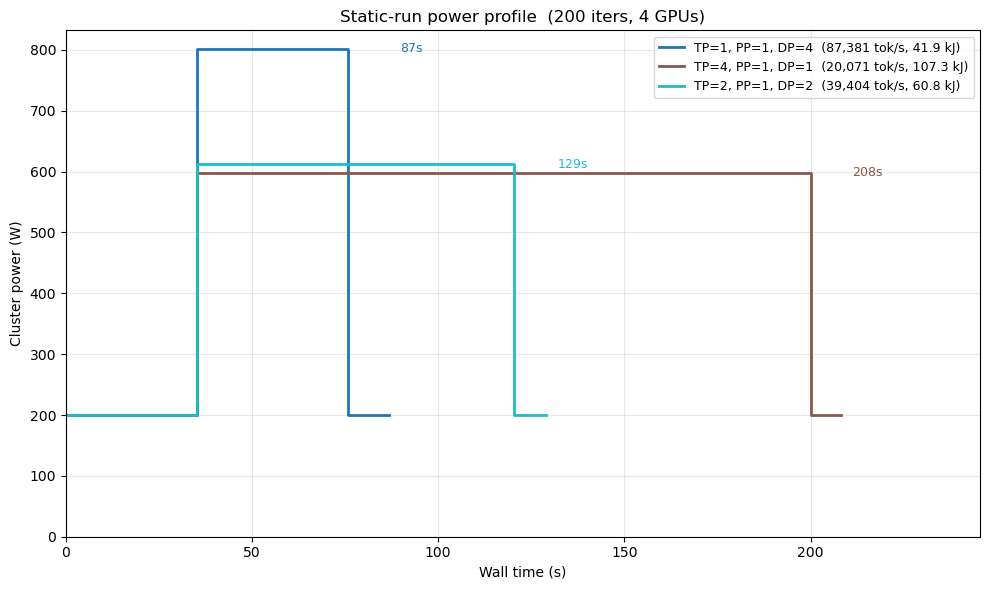

In [574]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.tab10(np.linspace(0, 1, max(len(sims), 1)))

for sim, color in zip(sims, colors):
    times    = sim['times']
    energies = sim['energies']
    phase_powers = np.diff(energies) / np.diff(times)

    plot_x = np.repeat(times, 2)[1:-1]
    plot_y = np.repeat(phase_powers, 2)

    label = (f"TP={sim['tp']}, PP={sim['pp']}, DP={sim['dp']}  "
             f"({sim['throughput_tok_s']:,.0f} tok/s, "
             f"{sim['total_energy_j']/1000:.1f} kJ)")
    ax.plot(plot_x, plot_y, '-', color=color, linewidth=2, label=label)

    steady_power = phase_powers[2]
    ax.annotate(f"{sim['wall_s']:.0f}s",
                xy=(sim['wall_s'], steady_power),
                xytext=(8, 0), textcoords='offset points',
                fontsize=9, color=color, va='center')

ax.set_xlabel('Wall time (s)')
ax.set_ylabel('Cluster power (W)')
ax.set_title(f"Static-run power profile  "
             f"({N_ITERS} iters, {N_GPUS} GPUs)")
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

xmax = max(s['wall_s'] for s in sims)
ax.set_xlim(0, xmax * 1.18)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()


## Predicted Summary


In [575]:
sims_sorted = sorted(sims, key=lambda s: s['total_energy_j'])

print(f"{'(TP,PP)':>8}  {'tok/s':>10}  {'wall (s)':>10}  {'wall (min)':>10}  "
      f"{'energy (kJ)':>12}  {'kWh':>9}  {'avg P (W)':>10}  {'J/tok':>8}")
print('-' * 100)
for sim in sims_sorted:
    tag = f"({sim['tp']},{sim['pp']})"
    print(f"{tag:>8}  {sim['throughput_tok_s']:>10,.0f}  "
          f"{sim['wall_s']:>10.1f}  {sim['wall_s']/60:>10.2f}  "
          f"{sim['total_energy_j']/1000:>12.1f}  "
          f"{sim['total_energy_j']/3.6e6:>9.5f}  "
          f"{sim['avg_power_w']:>10.1f}  "
          f"{sim['energy_per_token_j']:>8.4f}")

if len(sims_sorted) >= 2:
    best, worst = sims_sorted[0], sims_sorted[-1]
    savings = (1 - best['total_energy_j'] / worst['total_energy_j']) * 100
    speedup = worst['wall_s'] / best['wall_s']
    print(f"\nChoosing ({best['tp']},{best['pp']}) over "
          f"({worst['tp']},{worst['pp']}) for {N_ITERS} iters:")
    print(f"  Energy savings: {savings:.1f}%")
    print(f"  Wall speedup:   {speedup:.2f}x")


 (TP,PP)       tok/s    wall (s)  wall (min)   energy (kJ)        kWh   avg P (W)     J/tok
----------------------------------------------------------------------------------------------------
   (1,1)      87,381        86.9        1.45          41.9    0.01163       481.7    0.0128
   (2,1)      39,404       129.1        2.15          60.8    0.01690       471.4    0.0186
   (4,1)      20,071       208.1        3.47         107.3    0.02980       515.7    0.0327

Choosing (1,1) over (4,1) for 200 iters:
  Energy savings: 61.0%
  Wall speedup:   2.39x


## Actual Run Data


In [576]:
import pandas as pd

POWER_LOG_DIR = '/bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/gpt2_medium'

actual_runs = {
    (1, 1): f'{POWER_LOG_DIR}/elastic__static_tp1_pp1_power.csv',
    (2, 1): f'{POWER_LOG_DIR}/elastic__static_tp2_pp1_power.csv',
    (4, 1): f'{POWER_LOG_DIR}/elastic__static_tp4_pp1_power.csv',
}

df_peek = pd.read_csv(actual_runs[(1, 1)])
print("Columns:", df_peek.columns.tolist())
print(f"Rows:    {len(df_peek)}")
print(df_peek.head())
print("...")
print(df_peek.tail())


Columns: ['timestamp', 'time_step', 'total_power_W', 'GPU_0_W', 'GPU_1_W', 'GPU_2_W', 'GPU_3_W']
Rows:    165
                    timestamp  time_step  total_power_W  GPU_0_W  GPU_1_W  \
0  2026-05-14T11:39:06.739531          0         243.86    61.35    60.68   
1  2026-05-14T11:39:07.241534          0         243.21    61.02    60.68   
2  2026-05-14T11:39:07.741765          0         243.54    61.02    60.68   
3  2026-05-14T11:39:08.241860          0         243.54    61.02    60.68   
4  2026-05-14T11:39:08.741955          0         243.54    61.35    60.68   

   GPU_2_W  GPU_3_W  
0    60.40    61.43  
1    60.08    61.43  
2    60.40    61.43  
3    60.40    61.43  
4    60.08    61.43  
...
                      timestamp  time_step  total_power_W  GPU_0_W  GPU_1_W  \
160  2026-05-14T11:40:26.833976        200         273.01    68.30    68.65   
161  2026-05-14T11:40:27.334182        200         273.01    68.30    68.65   
162  2026-05-14T11:40:27.834413        200         276

## Power Log Loader


In [577]:
def load_power_csv(path: str):
    """Load PowerMonitor CSV → (t_seconds_since_start, cluster_power_w).
    Handles both numeric time (seconds, epoch, etc.) and ISO datetime strings."""
    df = pd.read_csv(path)
    df.columns = [c.lower() for c in df.columns]
    cols = df.columns.tolist()

    time_candidates  = ['time_s', 'time', 'timestamp', 'elapsed_s', 'elapsed', 't']
    power_candidates = ['total_power_w', 'cluster_power_w', 'total_w',
                        'power_w', 'power', 'cluster_w', 'sum', 'total']

    time_col  = next((c for c in time_candidates  if c in cols), None)
    power_col = next((c for c in power_candidates if c in cols), None)

    if time_col is None:
        raise ValueError(f"No time column in {path}. Found: {cols}")
    if power_col is None:
        gpu_cols = [c for c in cols if c.startswith('gpu')]
        if not gpu_cols:
            raise ValueError(f"No power column in {path}. Found: {cols}")
        df['_total'] = df[gpu_cols].sum(axis=1)
        power_col = '_total'

    time_raw = df[time_col]
    if pd.api.types.is_numeric_dtype(time_raw):
        t = time_raw.values.astype(float)
    else:
        ts = pd.to_datetime(time_raw)
        t = (ts - ts.iloc[0]).dt.total_seconds().values

    p = df[power_col].values.astype(float)
    return t - t[0], p


## Actual Trace Loading


In [578]:
actuals = {}
for key, path in actual_runs.items():
    t, p = load_power_csv(path)
    actuals[key] = {'t': t, 'p': p}
    print(f"  ({key[0]},{key[1]}): {len(t)} samples, "
          f"duration {t[-1]:.1f}s, full-trace mean = {p.mean():.1f}W")


  (1,1): 165 samples, duration 82.1s, full-trace mean = 510.9W
  (2,1): 256 samples, duration 127.6s, full-trace mean = 490.4W
  (4,1): 414 samples, duration 206.7s, full-trace mean = 528.2W


## Predicted vs Actual Power


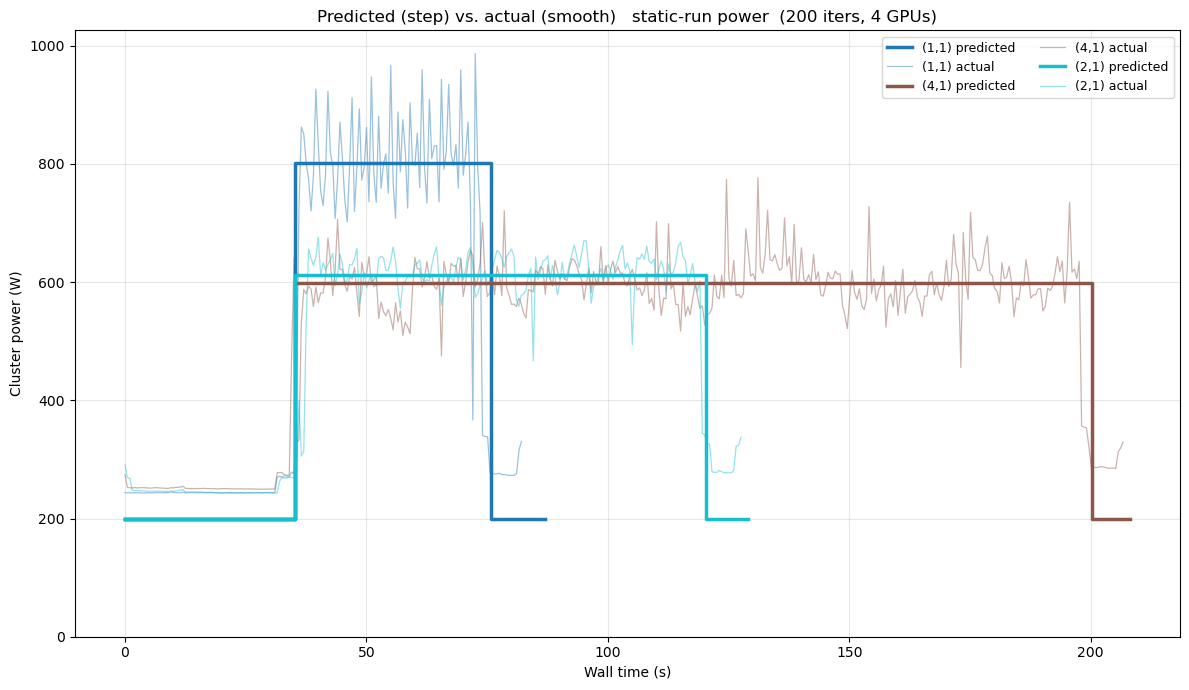

In [579]:
strategies_by_key = {(s['tp'], s['pp']): s for s in strategies}

fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.cm.tab10(np.linspace(0, 1, max(len(sims), 1)))

for sim, color in zip(sims, colors):
    times    = sim['times']
    energies = sim['energies']
    phase_powers = np.diff(energies) / np.diff(times)

    plot_x = np.repeat(times, 2)[1:-1]
    plot_y = np.repeat(phase_powers, 2)
    ax.plot(plot_x, plot_y, '-', color=color, linewidth=2.5,
            label=f"({sim['tp']},{sim['pp']}) predicted", zorder=3)

    key = (sim['tp'], sim['pp'])
    if key in actuals:
        ax.plot(actuals[key]['t'], actuals[key]['p'],
                '-', color=color, linewidth=0.9, alpha=0.45,
                label=f"({sim['tp']},{sim['pp']}) actual", zorder=2)

ax.set_xlabel('Wall time (s)')
ax.set_ylabel('Cluster power (W)')
ax.set_title(f"Predicted (step) vs. actual (smooth)   "
             f"static-run power  ({N_ITERS} iters, {N_GPUS} GPUs)")
ax.legend(loc='best', fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()


## Numerical Comparison


In [580]:
print(f"{'(TP,PP)':>8}  {'pred P (W)':>11}  {'act P (W)':>10}  {'dP':>7}  "
      f"{'pred wall':>10}  {'act wall':>10}  {'dwall':>7}")
print('-' * 78)

WARMUP_SKIP_S = 15.0
SAVE_SKIP_S   = 10.0

for sim in sims:
    key = (sim['tp'], sim['pp'])
    if key not in actuals:
        continue

    t = actuals[key]['t']
    p = actuals[key]['p']

    if t[-1] > (WARMUP_SKIP_S + SAVE_SKIP_S + 10):
        mask = (t > WARMUP_SKIP_S) & (t < t[-1] - SAVE_SKIP_S)
    else:
        mask = (t > 5) & (t < t[-1] - 3)
    actual_steady_p = p[mask].mean() if mask.any() else float('nan')
    actual_wall_s   = t[-1]

    pred_steady_p = strategies_by_key[key]['power_w']
    pred_wall_s   = sim['wall_s']

    dp_pct = (actual_steady_p - pred_steady_p) / pred_steady_p * 100
    dw_pct = (actual_wall_s   - pred_wall_s)   / pred_wall_s   * 100

    tag = f"({sim['tp']},{sim['pp']})"
    print(f"{tag:>8}  {pred_steady_p:>11.1f}  {actual_steady_p:>10.1f}  "
          f"{dp_pct:>+6.1f}%  "
          f"{pred_wall_s:>10.1f}  {actual_wall_s:>10.1f}  "
          f"{dw_pct:>+6.1f}%")


 (TP,PP)   pred P (W)   act P (W)       dP   pred wall    act wall    dwall
------------------------------------------------------------------------------
   (1,1)        802.0       604.5   -24.6%        86.9        82.1    -5.5%
   (4,1)        598.0       561.4    -6.1%       208.1       206.7    -0.7%
   (2,1)        612.0       539.6   -11.8%       129.1       127.6    -1.2%


## Hybrid Simulation


In [581]:
def validate_hybrid_schedule(schedule):
    if not schedule:
        raise ValueError('HYBRID_SCHEDULE must contain at least one phase')

    for prev, curr in zip(schedule, schedule[1:]):
        if prev['end_step'] != curr['start_step']:
            raise ValueError('HYBRID_SCHEDULE phases must be contiguous')

    for phase in schedule:
        if phase['end_step'] <= phase['start_step']:
            raise ValueError(f'Invalid phase bounds: {phase}')


def simulate_hybrid(schedule, strategies_by_key, reshard_time_s):
    validate_hybrid_schedule(schedule)

    times = [0.0]
    energies = [0.0]
    annotations = []

    def advance(dt, power_w, label=None):
        if dt <= 0:
            return
        times.append(times[-1] + dt)
        energies.append(energies[-1] + power_w * dt)
        if label is not None:
            annotations.append({'label': label, 'time_s': times[-1]})

    idle_cluster_w = IDLE_POWER_PER_GPU_W * N_GPUS
    advance(CONTAINER_STARTUP_S + FRESH_BUILD_S, idle_cluster_w, 'startup')

    for phase_idx, phase in enumerate(schedule):
        key = (phase['tp'], phase['pp'])
        if key not in strategies_by_key:
            raise ValueError(f'No strategy calibration for TP/PP={key}')

        strategy = strategies_by_key[key]
        phase_iters = phase['end_step'] - phase['start_step']
        warmup_iters = min(phase_iters, strategy['warmup_iters'])
        warmup_fraction = warmup_iters / strategy['warmup_iters'] if strategy['warmup_iters'] else 0.0
        warmup_s = strategy['warmup_wall_s'] * warmup_fraction
        steady_iters = max(0, phase_iters - warmup_iters)
        steady_s = steady_iters * strategy['step_time_s']

        advance(warmup_s, strategy['power_w'], f'phase {phase_idx} warmup')
        advance(steady_s, strategy['power_w'], f'phase {phase_idx} steady')

        if phase_idx < len(schedule) - 1:
            reshard_start = times[-1]
            cache_miss_s = FIRST_RESHARD_CACHE_MISS_S if phase_idx == 0 else 0.0
            advance(reshard_time_s + cache_miss_s, idle_cluster_w)
            annotations.append({'label': f'reshard {phase_idx}',
                                'start_s': reshard_start,
                                'end_s': times[-1]})

    last_strategy = strategies_by_key[(schedule[-1]['tp'], schedule[-1]['pp'])]
    advance(last_strategy['save_s'], idle_cluster_w, 'final save')

    n_iters = schedule[-1]['end_step'] - schedule[0]['start_step']
    total_tokens = n_iters * tokens_per_iter
    wall_s = times[-1]
    total_energy_j = energies[-1]

    return {
        'name': 'hybrid',
        'schedule': schedule,
        'n_iters': n_iters,
        'times': np.array(times),
        'energies': np.array(energies),
        'wall_s': wall_s,
        'total_wall_s': wall_s,
        'total_energy_j': total_energy_j,
        'avg_power_w': total_energy_j / wall_s if wall_s > 0 else 0.0,
        'energy_per_iter_j': total_energy_j / n_iters if n_iters > 0 else 0.0,
        'energy_per_token_j': total_energy_j / total_tokens if total_tokens > 0 else 0.0,
        'annotations': annotations,
    }


hybrid = simulate_hybrid(HYBRID_SCHEDULE, strategies_by_key, RESHARD_TIME_S)

print(f"Hybrid wall_s:      {hybrid['wall_s']:.1f}")
print(f"Hybrid energy_j:    {hybrid['total_energy_j']:.1f}")
print(f"Hybrid avg_power_w: {hybrid['avg_power_w']:.1f}")


Hybrid wall_s:      186.1
Hybrid energy_j:    79399.8
Hybrid avg_power_w: 426.6


## Hybrid Power Profile


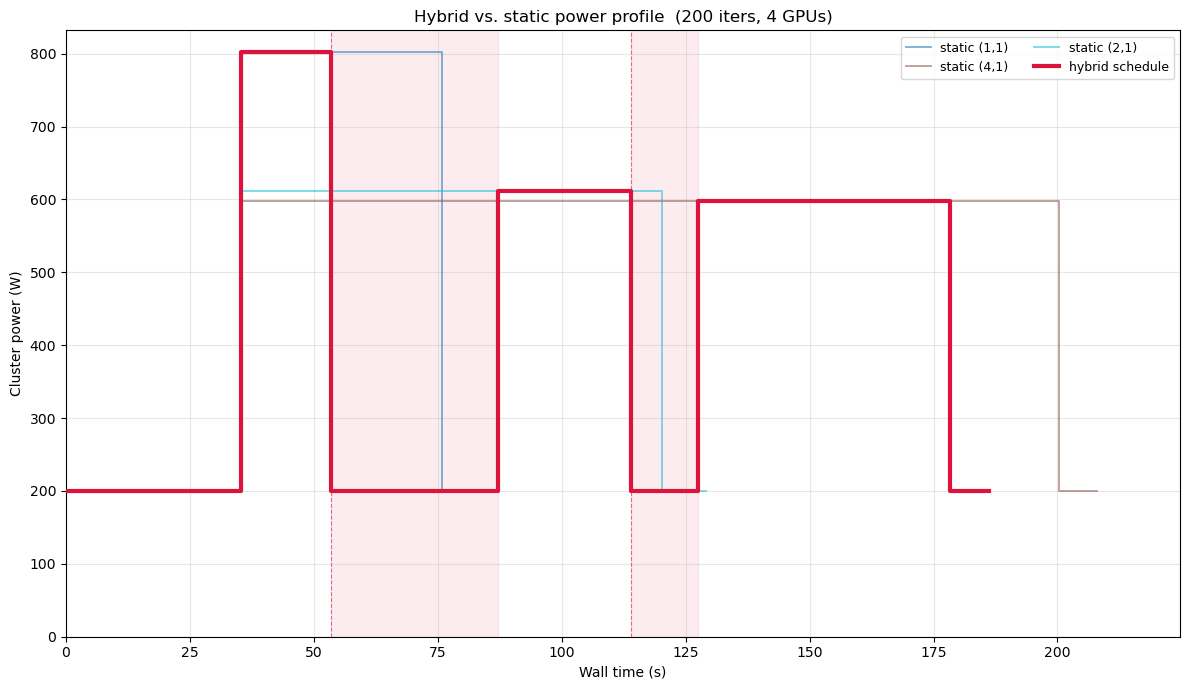

In [582]:
hybrid_n_iters = hybrid['n_iters']
hybrid_total_tokens = hybrid_n_iters * tokens_per_iter
static_baselines = [simulate(s, hybrid_total_tokens, tokens_per_iter,
                             FRESH_BUILD_S, idle_cluster_w)
                    for s in strategies]

fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.cm.tab10(np.linspace(0, 1, max(len(static_baselines), 1)))

for sim, color in zip(static_baselines, colors):
    times = sim['times']
    energies = sim['energies']
    phase_powers = np.diff(energies) / np.diff(times)
    plot_x = np.repeat(times, 2)[1:-1]
    plot_y = np.repeat(phase_powers, 2)
    ax.plot(plot_x, plot_y, '-', color=color, linewidth=1.4, alpha=0.55,
            label=f"static ({sim['tp']},{sim['pp']})")

hybrid_powers = np.diff(hybrid['energies']) / np.diff(hybrid['times'])
hybrid_x = np.repeat(hybrid['times'], 2)[1:-1]
hybrid_y = np.repeat(hybrid_powers, 2)
ax.plot(hybrid_x, hybrid_y, '-', color='crimson', linewidth=3.0,
        label='hybrid schedule', zorder=5)

for item in hybrid['annotations']:
    if item['label'].startswith('reshard') and 'start_s' in item:
        ax.axvspan(item['start_s'], item['end_s'], color='crimson', alpha=0.08)
        ax.axvline(item['start_s'], color='crimson', linestyle='--', linewidth=0.8, alpha=0.6)

ax.set_xlabel('Wall time (s)')
ax.set_ylabel('Cluster power (W)')
ax.set_title(f"Hybrid vs. static power profile  ({hybrid_n_iters} iters, {N_GPUS} GPUs)")
ax.legend(loc='best', fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
ax.set_xlim(0, max([hybrid['wall_s']] + [s['wall_s'] for s in static_baselines]) * 1.08)

plt.tight_layout()
plt.show()


## Hybrid Summary


In [583]:
comparison_rows = []
for sim in static_baselines:
    comparison_rows.append({
        'name': f"static ({sim['tp']},{sim['pp']})",
        'wall_s': sim['wall_s'],
        'energy_kj': sim['total_energy_j'] / 1000,
        'avg_power_w': sim['avg_power_w'],
        'j_iter': sim['total_energy_j'] / hybrid_n_iters,
    })

comparison_rows.append({
    'name': 'hybrid',
    'wall_s': hybrid['wall_s'],
    'energy_kj': hybrid['total_energy_j'] / 1000,
    'avg_power_w': hybrid['avg_power_w'],
    'j_iter': hybrid['energy_per_iter_j'],
})

print(f"{'option':>14}  {'wall_s':>10}  {'energy_kJ':>11}  {'avg_P_W':>10}  {'J/iter':>10}")
print('-' * 65)
for row in comparison_rows:
    print(f"{row['name']:>14}  {row['wall_s']:>10.1f}  {row['energy_kj']:>11.1f}  "
          f"{row['avg_power_w']:>10.1f}  {row['j_iter']:>10.1f}")

energy_winner = min(comparison_rows, key=lambda row: row['energy_kj'])
wall_winner = min(comparison_rows, key=lambda row: row['wall_s'])
best_static_energy = min((row for row in comparison_rows if row['name'].startswith('static')),
                         key=lambda row: row['energy_kj'])
best_static_wall = min((row for row in comparison_rows if row['name'].startswith('static')),
                       key=lambda row: row['wall_s'])

hybrid_energy_delta = hybrid['total_energy_j'] / 1000 - best_static_energy['energy_kj']
hybrid_wall_delta = hybrid['wall_s'] - best_static_wall['wall_s']

print(f"\nEnergy winner: {energy_winner['name']}")
print(f"Wall-time winner: {wall_winner['name']}")
print(f"Hybrid energy vs best static: {hybrid_energy_delta:+.1f} kJ")
print(f"Hybrid wall vs best static:   {hybrid_wall_delta:+.1f} s")


        option      wall_s    energy_kJ     avg_P_W      J/iter
-----------------------------------------------------------------
  static (1,1)        86.9         41.9       481.7       209.3
  static (4,1)       208.1        107.3       515.7       536.5
  static (2,1)       129.1         60.8       471.4       304.2
        hybrid       186.1         79.4       426.6       397.0

Energy winner: static (1,1)
Wall-time winner: static (1,1)
Hybrid energy vs best static: +37.5 kJ
Hybrid wall vs best static:   +99.2 s


## Load Hybrid Actual CSV


In [584]:
HYBRID_ACTUAL_PATH = f'{POWER_LOG_DIR}/elastic__hybrid_v1_power.csv'
t_hyb, p_hyb = load_power_csv(HYBRID_ACTUAL_PATH)
hybrid_actual = {'t': t_hyb, 'p': p_hyb}

print(f"Hybrid actual: {len(t_hyb)} samples, "
      f"duration {t_hyb[-1]:.1f}s, "
      f"full-trace mean = {p_hyb.mean():.1f}W")


Hybrid actual: 389 samples, duration 194.1s, full-trace mean = 462.2W


## Predicted vs Actual Hybrid


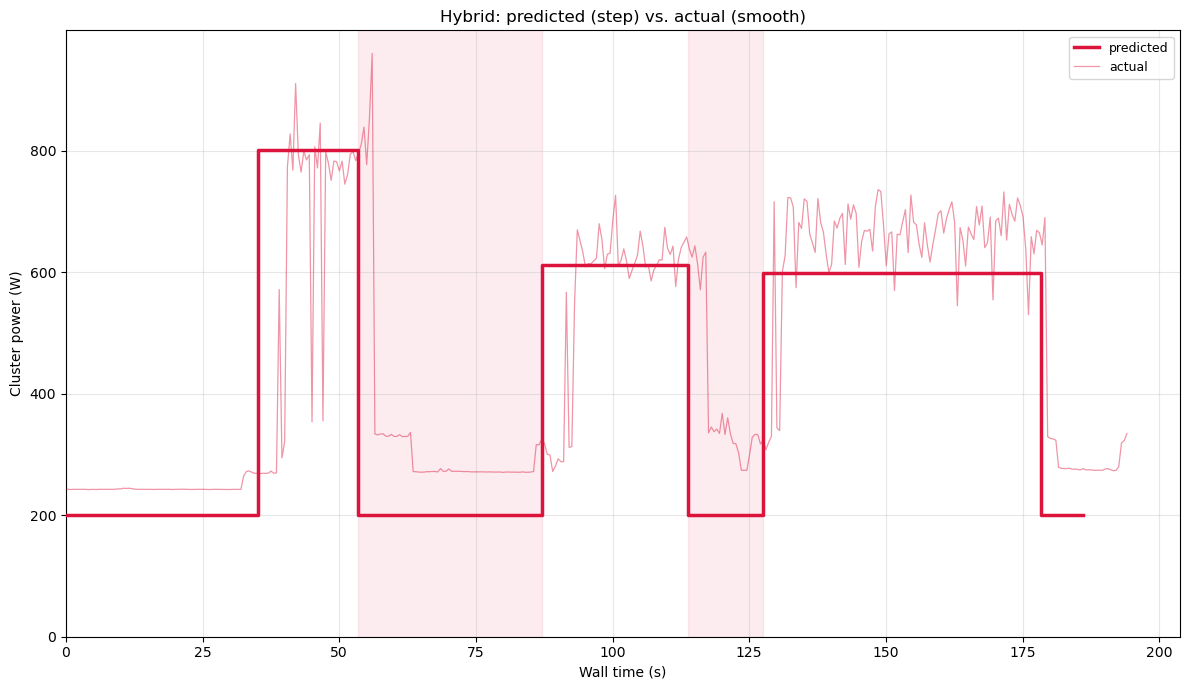

In [585]:
fig, ax = plt.subplots(figsize=(12, 7))

hybrid_powers = np.diff(hybrid['energies']) / np.diff(hybrid['times'])
hybrid_x = np.repeat(hybrid['times'], 2)[1:-1]
hybrid_y = np.repeat(hybrid_powers, 2)

ax.plot(hybrid_x, hybrid_y, '-', color='crimson', linewidth=2.5,
        label='predicted', zorder=4)
ax.plot(hybrid_actual['t'], hybrid_actual['p'], '-', color='crimson',
        linewidth=0.9, alpha=0.45, label='actual', zorder=3)

for item in hybrid['annotations']:
    if item['label'].startswith('reshard') and 'start_s' in item:
        ax.axvspan(item['start_s'], item['end_s'], color='crimson', alpha=0.08)

ax.set_xlabel('Wall time (s)')
ax.set_ylabel('Cluster power (W)')
ax.set_title('Hybrid: predicted (step) vs. actual (smooth)')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
ax.set_xlim(0, max(hybrid['wall_s'], t_hyb[-1]) * 1.05)

plt.tight_layout()
plt.show()


## Combined Predicted and Actual Comparison


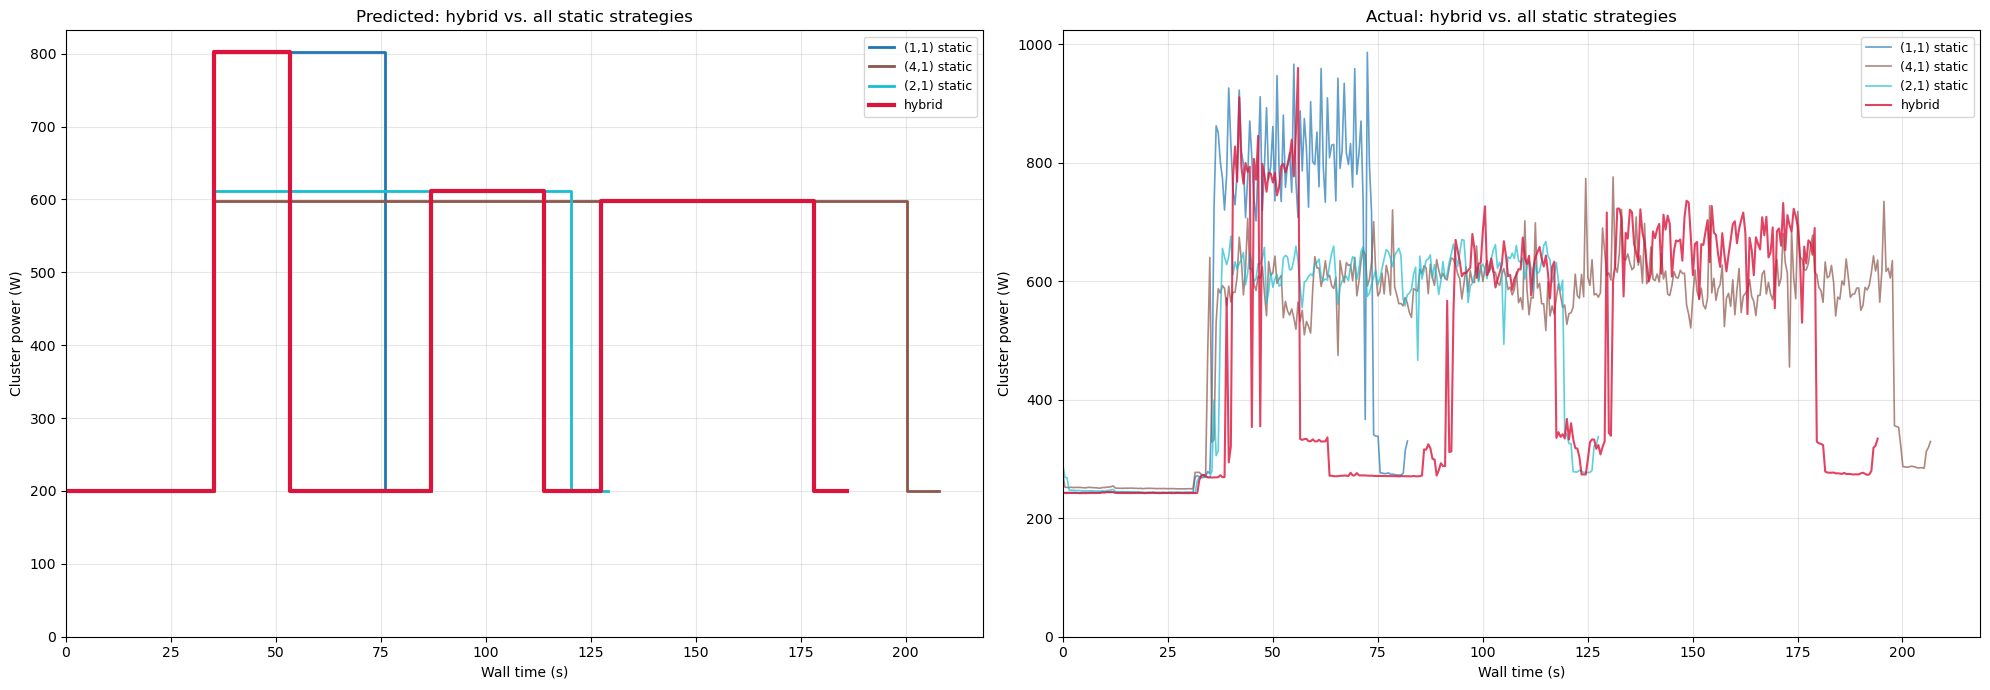

In [586]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
colors = plt.cm.tab10(np.linspace(0, 1, max(len(sims), 1)))

predicted_walls = [sim['wall_s'] for sim in sims] + [hybrid['wall_s']]
actual_walls = [actuals[(sim['tp'], sim['pp'])]['t'][-1]
                for sim in sims if (sim['tp'], sim['pp']) in actuals]
actual_walls.append(hybrid_actual['t'][-1])
shared_xlim = max(predicted_walls + actual_walls) * 1.05

for sim, color in zip(sims, colors):
    times = sim['times']
    energies = sim['energies']
    powers = np.diff(energies) / np.diff(times)
    plot_x = np.repeat(times, 2)[1:-1]
    plot_y = np.repeat(powers, 2)
    ax[0].plot(plot_x, plot_y, '-', color=color, linewidth=2,
               label=f"({sim['tp']},{sim['pp']}) static")

hybrid_powers = np.diff(hybrid['energies']) / np.diff(hybrid['times'])
hybrid_x = np.repeat(hybrid['times'], 2)[1:-1]
hybrid_y = np.repeat(hybrid_powers, 2)
ax[0].plot(hybrid_x, hybrid_y, '-', color='crimson', linewidth=3,
           label='hybrid')

for sim, color in zip(sims, colors):
    key = (sim['tp'], sim['pp'])
    if key not in actuals:
        continue
    ax[1].plot(actuals[key]['t'], actuals[key]['p'], '-', color=color,
               linewidth=1.2, alpha=0.7,
               label=f"({sim['tp']},{sim['pp']}) static")

ax[1].plot(hybrid_actual['t'], hybrid_actual['p'], '-', color='crimson',
           linewidth=1.5, alpha=0.8, label='hybrid')

ax[0].set_title('Predicted: hybrid vs. all static strategies')
ax[1].set_title('Actual: hybrid vs. all static strategies')

for axis in ax:
    axis.set_xlabel('Wall time (s)')
    axis.set_ylabel('Cluster power (W)')
    axis.grid(True, alpha=0.3)
    axis.set_ylim(bottom=0)
    axis.set_xlim(0, shared_xlim)
    axis.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()


## Hybrid Validation Table


In [587]:
rows = []
for sim in sims:
    key = (sim['tp'], sim['pp'])
    if key not in actuals:
        continue

    actual_wall = actuals[key]['t'][-1]
    actual_energy_j = np.trapezoid(actuals[key]['p'], actuals[key]['t'])
    rows.append({
        'option': f"static ({sim['tp']},{sim['pp']})",
        'predicted_wall': sim['wall_s'],
        'actual_wall': actual_wall,
        'pred_energy_j': sim['total_energy_j'],
        'actual_energy_j': actual_energy_j,
    })

rows.append({
    'option': 'hybrid',
    'predicted_wall': hybrid['wall_s'],
    'actual_wall': hybrid_actual['t'][-1],
    'pred_energy_j': hybrid['total_energy_j'],
    'actual_energy_j': np.trapezoid(hybrid_actual['p'], hybrid_actual['t']),
})

print(f"{'option':>14}  {'predicted_wall':>15}  {'actual_wall':>12}  {'dwall%':>8}  "
      f"{'pred_energy_kJ':>15}  {'actual_energy_kJ':>17}  {'denergy%':>9}")
print('-' * 100)

for row in rows:
    dwall_pct = (row['actual_wall'] - row['predicted_wall']) / row['predicted_wall'] * 100
    pred_energy_kj = row['pred_energy_j'] / 1000
    actual_energy_kj = row['actual_energy_j'] / 1000
    denergy_pct = (actual_energy_kj - pred_energy_kj) / pred_energy_kj * 100
    print(f"{row['option']:>14}  {row['predicted_wall']:>15.1f}  "
          f"{row['actual_wall']:>12.1f}  {dwall_pct:>+7.1f}%  "
          f"{pred_energy_kj:>15.1f}  {actual_energy_kj:>17.1f}  "
          f"{denergy_pct:>+8.1f}%")


        option   predicted_wall   actual_wall    dwall%   pred_energy_kJ   actual_energy_kJ   denergy%
----------------------------------------------------------------------------------------------------
  static (1,1)             86.9          82.1     -5.5%             41.9               42.0      +0.4%
  static (4,1)            208.1         206.7     -0.7%            107.3              109.3      +1.8%
  static (2,1)            129.1         127.6     -1.2%             60.8               62.6      +2.9%
        hybrid            186.1         194.1     +4.3%             79.4               89.8     +13.1%


## Load Carbon Trace


In [588]:
def load_carbon_trace(path):
    df = pd.read_csv(path)
    required = {'year', 'month', 'day', 'time', 'carbon'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'Carbon trace missing columns: {sorted(missing)}')

    datetimes = pd.to_datetime(
        df['year'].astype(str) + '-' +
        df['month'].astype(str).str.zfill(2) + '-' +
        df['day'].astype(str).str.zfill(2) + ' ' +
        df['time'].astype(str)
    )
    df = df.assign(datetime=datetimes).sort_values('datetime').reset_index(drop=True)

    t = (df['datetime'] - df['datetime'].iloc[0]).dt.total_seconds().to_numpy(dtype=float)
    c = df['carbon'].to_numpy(dtype=float)
    datetimes = df['datetime']

    if len(t) >= 2:
        dt = np.diff(t)
        if not np.allclose(dt, 3600.0):
            raise ValueError('Carbon trace must be hourly with exactly 3600 seconds between rows')

    last_covered_s = t[-1] + 3600.0
    requested_end_s = TRACE_START_OFFSET_S + SIMULATION_DURATION_S
    if requested_end_s > last_covered_s:
        overrun_h = (requested_end_s - last_covered_s) / 3600.0
        print(f'Warning: simulation exceeds carbon trace by {overrun_h:.2f}h; clamping at last CI value')

    print(f"Carbon trace: {len(c)} hourly entries, "
          f"{datetimes.iloc[0]} to {datetimes.iloc[-1]}, "
          f"CI min/max/mean = {c.min():.1f}/{c.max():.1f}/{c.mean():.1f} g/kWh")
    return t, c, datetimes


trace_t, trace_ci, trace_datetimes = load_carbon_trace(CARBON_TRACE_PATH)


Carbon trace: 24 hourly entries, 2026-05-08 06:00:00 to 2026-05-09 05:00:00, CI min/max/mean = 53.0/139.0/92.5 g/kWh


## Carbon Intensity Lookup


In [589]:
def ci_at(t_sim, trace_t, trace_ci, trace_offset_s):
    trace_time = float(t_sim) + trace_offset_s
    if trace_time <= trace_t[0]:
        return float(trace_ci[0])
    if trace_time >= trace_t[-1] + 3600.0:
        return float(trace_ci[-1])

    idx = np.searchsorted(trace_t, trace_time, side='right') - 1
    idx = int(np.clip(idx, 0, len(trace_ci) - 1))
    return float(trace_ci[idx])


## Carbon-Aware Static Model


In [590]:

def simulate_under_carbon(strategy,
                          total_tokens,
                          trace_t,
                          trace_ci,
                          trace_offset_s,
                          fresh_build_s,
                          idle_cluster_w,
                          container_startup_s,
                          tokens_per_iter):
    power_w = strategy['power_w']
    warmup_s = float(strategy['warmup_wall_s'])
    warmup_tokens = float(strategy['warmup_iters'] * tokens_per_iter)
    save_s = float(strategy['save_s'])
    total_tokens = float(total_tokens)

    startup_end = container_startup_s + fresh_build_s

    if warmup_s > 0 and warmup_tokens > 0:
        tokens_per_warmup_s = warmup_tokens / warmup_s
        actual_warmup_s = min(warmup_s, total_tokens / tokens_per_warmup_s)
        tokens_after_warmup = max(0.0, total_tokens - tokens_per_warmup_s * actual_warmup_s)
    else:
        actual_warmup_s = 0.0
        tokens_after_warmup = total_tokens

    steady_s = tokens_after_warmup * strategy['step_time_s'] / tokens_per_iter if tokens_per_iter > 0 else 0.0
    warmup_end = startup_end + actual_warmup_s
    train_end = warmup_end + steady_s
    duration_s = train_end + save_s

    phase_points = [0.0, startup_end, warmup_end, train_end, duration_s]
    ci_points = []
    trace_start = trace_offset_s
    trace_end = trace_offset_s + duration_s
    for tick in trace_t:
        if trace_start < tick < trace_end:
            ci_points.append(float(tick - trace_offset_s))

    breakpoints = sorted(set(round(x, 9) for x in phase_points + ci_points if 0 <= x <= duration_s))
    if breakpoints[0] != 0.0:
        breakpoints.insert(0, 0.0)
    if breakpoints[-1] != duration_s:
        breakpoints.append(duration_s)

    times = [0.0]
    energies_j = [0.0]
    carbons_g = [0.0]
    powers = [idle_cluster_w]
    cis = [ci_at(0.0, trace_t, trace_ci, trace_offset_s)]

    def power_at(t_mid):
        if t_mid < startup_end:
            return idle_cluster_w
        if t_mid < train_end:
            return power_w
        return idle_cluster_w

    for t0, t1 in zip(breakpoints, breakpoints[1:]):
        dt = t1 - t0
        if dt <= 0:
            continue
        t_mid = t0 + dt / 2
        p = power_at(t_mid)
        ci = ci_at(t_mid, trace_t, trace_ci, trace_offset_s)
        de_j = p * dt
        dc_g = de_j * ci / 3.6e6

        times.append(t1)
        energies_j.append(energies_j[-1] + de_j)
        carbons_g.append(carbons_g[-1] + dc_g)
        powers.append(p)
        cis.append(ci)

    total_energy_j = energies_j[-1]
    total_carbon_g = carbons_g[-1]

    return {
        'tp': strategy['tp'],
        'pp': strategy['pp'],
        'dp': strategy.get('dp', N_GPUS // (strategy['tp'] * strategy['pp'])),
        'duration_s': duration_s,
        'times': np.array(times),
        'energies_j': np.array(energies_j),
        'carbons_g': np.array(carbons_g),
        'powers': np.array(powers),
        'cis': np.array(cis),
        'total_energy_j': total_energy_j,
        'total_carbon_g': total_carbon_g,
        'total_tokens': total_tokens,
        'avg_power_w': total_energy_j / duration_s if duration_s > 0 else 0.0,
        'avg_ci': total_carbon_g * 3.6e6 / total_energy_j if total_energy_j > 0 else 0.0,
    }


## Run Carbon-Aware Static Simulations


In [591]:

carbon_sims = [simulate_under_carbon(s,
                                     PRETRAINING_TOKENS,
                                     trace_t,
                                     trace_ci,
                                     TRACE_START_OFFSET_S,
                                     FRESH_BUILD_S,
                                     idle_cluster_w,
                                     CONTAINER_STARTUP_S,
                                     tokens_per_iter)
               for s in strategies]

print(f'Carbon-aware static simulations: {len(carbon_sims)} strategies, '
      f'{PRETRAINING_TOKENS / 1e9:.1f}B tokens each')


Carbon-aware static simulations: 3 strategies, 3.0B tokens each


## Carbon-Aware Static Plot


# TODO: We need to test a hybrid strategy here
Let's try the following custom proof-of-concept hybrid strategy:

When CI > 60, do TP = 4, PP = DP = 1 strategy. Else, do the DP = 4, PP = TP = 1 strategy

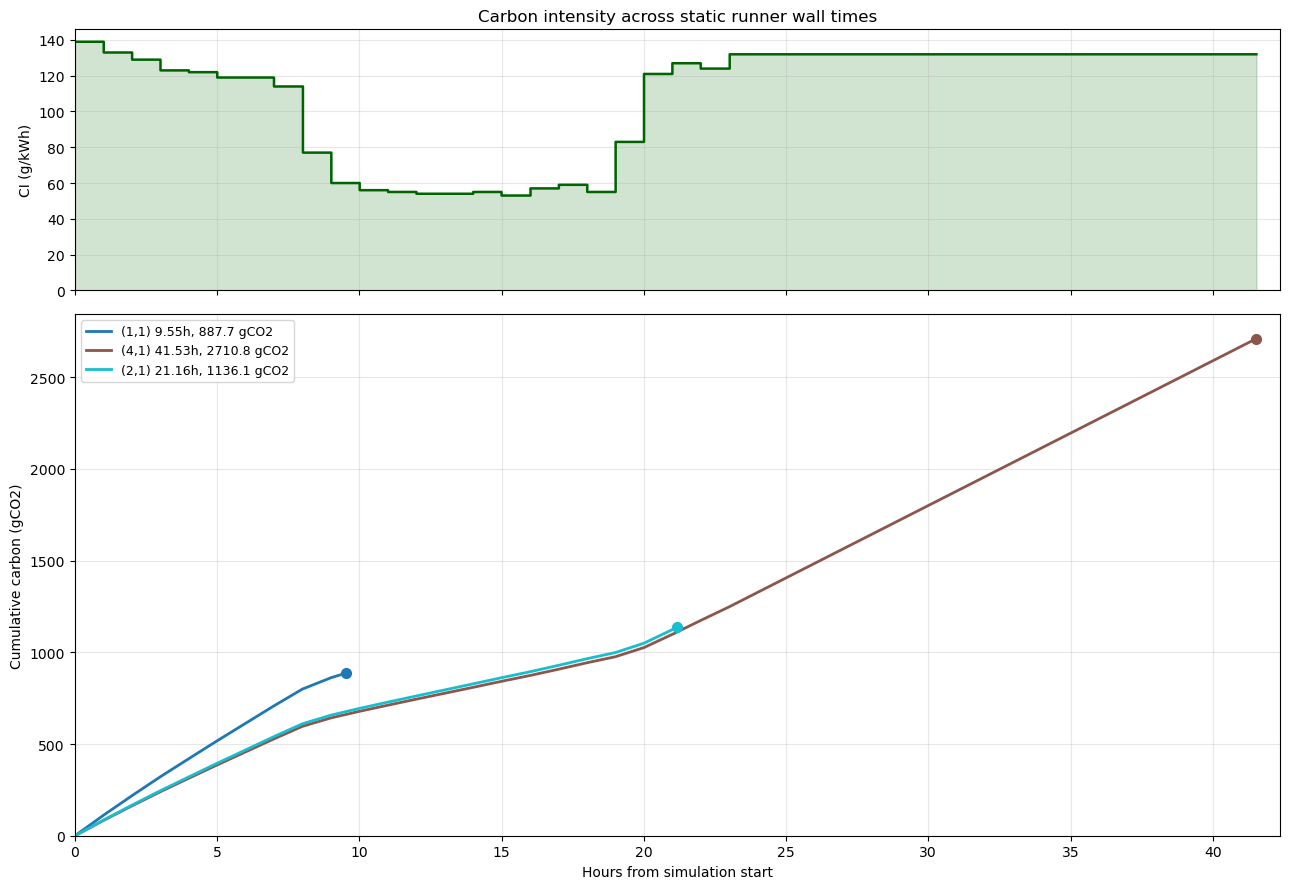

In [592]:

fig, (ax_ci, ax_c) = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                                  gridspec_kw={'height_ratios': [1, 2]})

max_static_hours = max(sim['duration_s'] for sim in carbon_sims) / 3600.0
sample_t = np.linspace(0, max_static_hours * 3600.0, 2000)
sample_ci = np.array([ci_at(t, trace_t, trace_ci, TRACE_START_OFFSET_S) for t in sample_t])
sample_h = sample_t / 3600.0

ax_ci.fill_between(sample_h, sample_ci, color='darkgreen', alpha=0.18, step='post')
ax_ci.plot(sample_h, sample_ci, color='darkgreen', linewidth=1.8, drawstyle='steps-post')
ax_ci.set_ylabel('CI (g/kWh)')
ax_ci.set_title(f'Carbon intensity across static runner wall times')
ax_ci.grid(True, alpha=0.3)
ax_ci.set_ylim(bottom=0)

colors = plt.cm.tab10(np.linspace(0, 1, max(len(carbon_sims), 1)))
for sim, color in zip(carbon_sims, colors):
    label = (f"({sim['tp']},{sim['pp']}) "
             f"{sim['duration_s'] / 3600.0:.2f}h, {sim['total_carbon_g']:.1f} gCO2")
    ax_c.plot(sim['times'] / 3600.0, sim['carbons_g'], color=color, linewidth=2,
              label=label)
    ax_c.plot(sim['duration_s'] / 3600.0, sim['total_carbon_g'], 'o',
              color=color, markersize=7)

ax_c.set_xlabel('Hours from simulation start')
ax_c.set_ylabel('Cumulative carbon (gCO2)')
ax_c.legend(loc='upper left', fontsize=9)
ax_c.grid(True, alpha=0.3)
ax_c.set_ylim(bottom=0)
ax_c.set_xlim(0, max_static_hours * 1.02)

plt.tight_layout()
plt.show()


## Carbon-Aware Static Summary


In [593]:

carbon_sims_sorted = sorted(carbon_sims, key=lambda s: s['total_carbon_g'])

print(f"{'(TP,PP)':>8}  {'wall (h)':>9}  {'energy (kWh)':>13}  "
      f"{'carbon (gCO2)':>14}  {'avg P (W)':>10}  {'avg CI':>8}")
print('-' * 76)

for sim in carbon_sims_sorted:
    tag = f"({sim['tp']},{sim['pp']})"
    energy_kwh = sim['total_energy_j'] / 3.6e6
    print(f"{tag:>8}  {sim['duration_s'] / 3600.0:>9.2f}  {energy_kwh:>13.4f}  "
          f"{sim['total_carbon_g']:>14.1f}  {sim['avg_power_w']:>10.1f}  {sim['avg_ci']:>8.1f}")


 (TP,PP)   wall (h)   energy (kWh)   carbon (gCO2)   avg P (W)    avg CI
----------------------------------------------------------------------------
   (1,1)       9.55         7.6517           887.7       801.2     116.0
   (2,1)      21.16        12.9458          1136.1       611.8      87.8
   (4,1)      41.53        24.8311          2710.8       597.9     109.2


## Carbon-Aware CI-Threshold Dynamic Strategy


In [594]:
HIGH_CI_KEY = (4, 1)
LOW_CI_KEY = (1, 1)
CI_THRESHOLD_G_PER_KWH = 60.0

missing_threshold_keys = [key for key in (HIGH_CI_KEY, LOW_CI_KEY) if key not in strategies_by_key]
if missing_threshold_keys:
    raise KeyError(f'Missing CI-threshold strategies: {missing_threshold_keys}')


def simulate_ci_threshold(strategies_by_key,
                          high_ci_key,
                          low_ci_key,
                          threshold_g_per_kwh,
                          total_tokens,
                          trace_t,
                          trace_ci,
                          trace_offset_s,
                          fresh_build_s,
                          idle_cluster_w,
                          container_startup_s,
                          tokens_per_iter,
                          reshard_time_s,
                          first_reshard_cache_miss_s,
                          safety_iters=100_000):
    def choose_key(t_sim):
        ci = ci_at(t_sim, trace_t, trace_ci, trace_offset_s)
        key = high_ci_key if ci > threshold_g_per_kwh else low_ci_key
        return key, ci

    def next_trace_hour_tick(t_sim):
        trace_time = t_sim + trace_offset_s
        next_tick = (np.floor(trace_time / 3600.0) + 1.0) * 3600.0
        return float(next_tick - trace_offset_s)

    def warmup_rate(strategy):
        warmup_s = float(strategy['warmup_wall_s'])
        if warmup_s <= 0:
            return 0.0
        return strategy['warmup_iters'] * tokens_per_iter / warmup_s

    segments = []
    annotations = []
    hour_assignments = []
    cursor = 0.0
    accumulated_tokens = 0.0
    prev_key = None
    last_key = low_ci_key
    reshard_count = 0

    def emit(duration_s, power, label, key=None):
        nonlocal cursor
        duration_s = max(0.0, float(duration_s))
        if duration_s <= 1e-9:
            return None
        segment = {
            'start': float(cursor),
            'end': float(cursor + duration_s),
            'power': float(power),
            'label': label,
            'key': key,
        }
        segments.append(segment)
        cursor += duration_s
        return segment

    emit(container_startup_s, idle_cluster_w, 'startup')
    emit(fresh_build_s, idle_cluster_w, 'build')

    for _ in range(safety_iters):
        if accumulated_tokens >= total_tokens - 1e-6:
            break

        key, ci = choose_key(cursor)
        strategy = strategies_by_key[key]
        hour_end = next_trace_hour_tick(cursor)
        if hour_end <= cursor + 1e-9:
            hour_end = cursor + 3600.0
        hour_assignments.append({
            'start_s': float(cursor),
            'end_s': float(hour_end),
            'key': key,
            'ci': float(ci),
        })

        strategy_changed = prev_key is not None and key != prev_key
        first_phase = prev_key is None

        if strategy_changed:
            reshard_count += 1
            t0 = cursor
            duration = reshard_time_s
            if reshard_count == 1:
                duration += first_reshard_cache_miss_s
            emit(duration, idle_cluster_w, 'reshard')
            annotations.append({
                'label': f'reshard {reshard_count}',
                'start_s': float(t0),
                'end_s': float(cursor),
                'from_key': prev_key,
                'to_key': key,
            })
            hour_end = next_trace_hour_tick(cursor)
            if hour_end <= cursor + 1e-9:
                hour_end = cursor + 3600.0

        if (first_phase or strategy_changed) and accumulated_tokens < total_tokens - 1e-6:
            rate = warmup_rate(strategy)
            if rate > 0:
                remaining_tokens = total_tokens - accumulated_tokens
                duration = min(float(strategy['warmup_wall_s']),
                               max(0.0, hour_end - cursor),
                               remaining_tokens / rate)
                if duration > 1e-9:
                    emit(duration, strategy['power_w'], 'warmup', key)
                    accumulated_tokens += rate * duration

        if accumulated_tokens < total_tokens - 1e-6:
            rate = tokens_per_iter / strategy['step_time_s'] if strategy['step_time_s'] > 0 else 0.0
            if rate <= 0:
                raise ValueError(f'Strategy {key} has non-positive steady throughput')
            remaining_tokens = total_tokens - accumulated_tokens
            duration = min(max(0.0, hour_end - cursor), remaining_tokens / rate)
            if duration > 1e-9:
                emit(duration, strategy['power_w'], 'train', key)
                accumulated_tokens += rate * duration

        prev_key = key
        last_key = key
    else:
        raise RuntimeError(f'CI-threshold simulation hit safety_iters={safety_iters}')

    emit(strategies_by_key[last_key]['save_s'], idle_cluster_w, 'save')
    duration_s = cursor

    segment_edges = [0.0, duration_s]
    for segment in segments:
        segment_edges.extend([segment['start'], segment['end']])

    ci_points = []
    trace_start = trace_offset_s
    trace_end = trace_offset_s + duration_s
    for tick in trace_t:
        if trace_start < tick < trace_end:
            ci_points.append(float(tick - trace_offset_s))

    breakpoints = sorted(set(round(x, 9) for x in segment_edges + ci_points if 0 <= x <= duration_s))
    if not breakpoints or breakpoints[0] != 0.0:
        breakpoints.insert(0, 0.0)
    if breakpoints[-1] != duration_s:
        breakpoints.append(duration_s)

    times = [0.0]
    energies_j = [0.0]
    carbons_g = [0.0]
    powers = [segments[0]['power'] if segments else idle_cluster_w]
    cis = [ci_at(0.0, trace_t, trace_ci, trace_offset_s)]

    def segment_at(t_mid):
        for segment in segments:
            if segment['start'] <= t_mid < segment['end']:
                return segment
        if segments and abs(t_mid - duration_s) < 1e-9:
            return segments[-1]
        return {'start': t_mid, 'end': t_mid, 'power': idle_cluster_w, 'label': 'idle', 'key': None}

    for t0, t1 in zip(breakpoints, breakpoints[1:]):
        dt = t1 - t0
        if dt <= 0:
            continue
        t_mid = t0 + dt / 2.0
        segment = segment_at(t_mid)
        p = segment['power']
        ci = ci_at(t_mid, trace_t, trace_ci, trace_offset_s)
        de_j = p * dt
        dc_g = de_j * ci / 3.6e6

        times.append(t1)
        energies_j.append(energies_j[-1] + de_j)
        carbons_g.append(carbons_g[-1] + dc_g)
        powers.append(p)
        cis.append(ci)

    total_energy_j = energies_j[-1]
    total_carbon_g = carbons_g[-1]

    return {
        'duration_s': duration_s,
        'threshold': threshold_g_per_kwh,
        'high_ci_key': high_ci_key,
        'low_ci_key': low_ci_key,
        'segments': segments,
        'annotations': annotations,
        'hour_assignments': hour_assignments,
        'times': np.array(times),
        'energies_j': np.array(energies_j),
        'carbons_g': np.array(carbons_g),
        'powers': np.array(powers),
        'cis': np.array(cis),
        'total_energy_j': total_energy_j,
        'total_carbon_g': total_carbon_g,
        'total_tokens': float(total_tokens),
        'avg_power_w': total_energy_j / duration_s if duration_s > 0 else 0.0,
        'avg_ci': total_carbon_g * 3.6e6 / total_energy_j if total_energy_j > 0 else 0.0,
    }


threshold_sim = simulate_ci_threshold(strategies_by_key,
                                      HIGH_CI_KEY,
                                      LOW_CI_KEY,
                                      CI_THRESHOLD_G_PER_KWH,
                                      PRETRAINING_TOKENS,
                                      trace_t,
                                      trace_ci,
                                      TRACE_START_OFFSET_S,
                                      FRESH_BUILD_S,
                                      idle_cluster_w,
                                      CONTAINER_STARTUP_S,
                                      tokens_per_iter,
                                      RESHARD_TIME_S,
                                      FIRST_RESHARD_CACHE_MISS_S)

print(f"CI-threshold dynamic simulation: {len(threshold_sim['segments'])} segments, "
      f"{len(threshold_sim['annotations'])} reshards, "
      f"{threshold_sim['duration_s'] / 3600.0:.2f}h wall")


CI-threshold dynamic simulation: 23 segments, 1 reshards, 16.49h wall


## Carbon-Aware CI-Threshold Plot


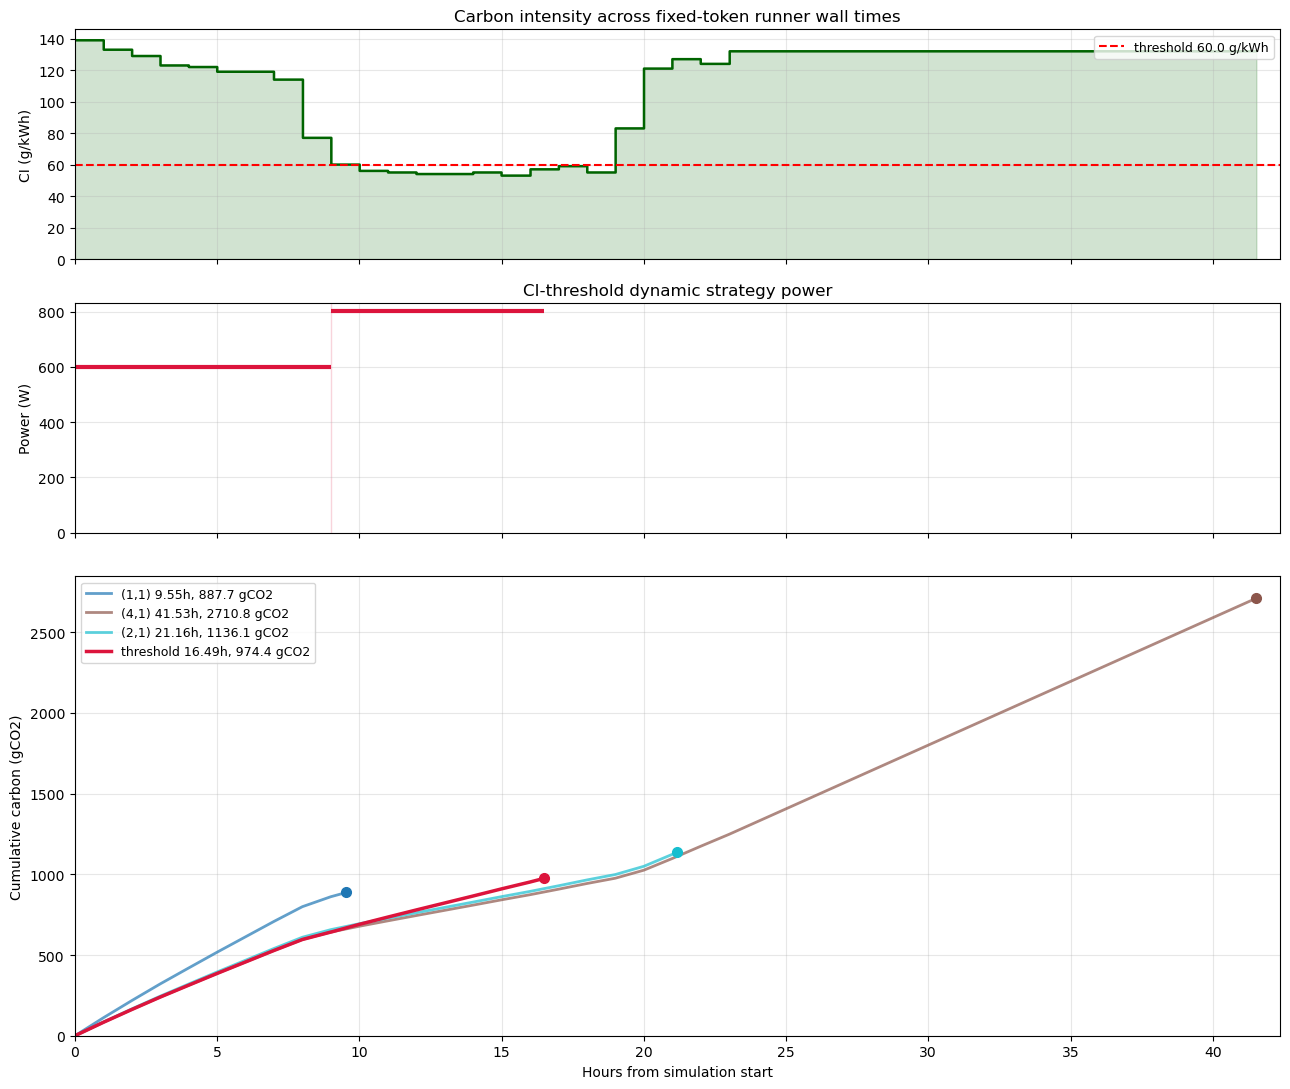

In [595]:

fig, (ax_ci, ax_p, ax_c) = plt.subplots(3, 1, figsize=(13, 11), sharex=True,
                                        gridspec_kw={'height_ratios': [1, 1, 2]})

max_hours = max([sim['duration_s'] for sim in carbon_sims] + [threshold_sim['duration_s']]) / 3600.0
sample_t = np.linspace(0, max_hours * 3600.0, 2000)
sample_ci = np.array([ci_at(t, trace_t, trace_ci, TRACE_START_OFFSET_S) for t in sample_t])
sample_h = sample_t / 3600.0

ax_ci.fill_between(sample_h, sample_ci, color='darkgreen', alpha=0.18, step='post')
ax_ci.plot(sample_h, sample_ci, color='darkgreen', linewidth=1.8, drawstyle='steps-post')
ax_ci.axhline(CI_THRESHOLD_G_PER_KWH, color='red', linestyle='--', linewidth=1.5,
              label=f'threshold {CI_THRESHOLD_G_PER_KWH:.1f} g/kWh')
ax_ci.set_ylabel('CI (g/kWh)')
ax_ci.set_title('Carbon intensity across fixed-token runner wall times')
ax_ci.legend(loc='upper right', fontsize=9)
ax_ci.grid(True, alpha=0.3)
ax_ci.set_ylim(bottom=0)

for segment in threshold_sim['segments']:
    ax_p.plot([segment['start'] / 3600.0, segment['end'] / 3600.0],
              [segment['power'], segment['power']],
              color='crimson', linewidth=3, solid_capstyle='butt')
for annotation in threshold_sim['annotations']:
    ax_p.axvspan(annotation['start_s'] / 3600.0,
                 annotation['end_s'] / 3600.0,
                 color='crimson', alpha=0.18)
ax_p.set_ylabel('Power (W)')
ax_p.set_title('CI-threshold dynamic strategy power')
ax_p.grid(True, alpha=0.3)
ax_p.set_ylim(bottom=0)

colors = plt.cm.tab10(np.linspace(0, 1, max(len(carbon_sims), 1)))
for sim, color in zip(carbon_sims, colors):
    label = (f"({sim['tp']},{sim['pp']}) "
             f"{sim['duration_s'] / 3600.0:.2f}h, {sim['total_carbon_g']:.1f} gCO2")
    ax_c.plot(sim['times'] / 3600.0, sim['carbons_g'], color=color, linewidth=2,
              alpha=0.7, label=label)
    ax_c.plot(sim['duration_s'] / 3600.0, sim['total_carbon_g'], 'o',
              color=color, markersize=7)

threshold_label = (f"threshold {threshold_sim['duration_s'] / 3600.0:.2f}h, "
                   f"{threshold_sim['total_carbon_g']:.1f} gCO2")
ax_c.plot(threshold_sim['times'] / 3600.0, threshold_sim['carbons_g'],
          color='crimson', linewidth=2.5, label=threshold_label)
ax_c.plot(threshold_sim['duration_s'] / 3600.0, threshold_sim['total_carbon_g'], 'o',
          color='crimson', markersize=7)

ax_c.set_xlabel('Hours from simulation start')
ax_c.set_ylabel('Cumulative carbon (gCO2)')
ax_c.legend(loc='upper left', fontsize=9)
ax_c.grid(True, alpha=0.3)
ax_c.set_ylim(bottom=0)
ax_c.set_xlim(0, max_hours * 1.02)

plt.tight_layout()
plt.show()


## Carbon-Aware CI-Threshold Summary


In [596]:

summary_rows = []
for sim in carbon_sims:
    summary_rows.append({
        'option': f"({sim['tp']},{sim['pp']})",
        'wall_h': sim['duration_s'] / 3600.0,
        'energy_kwh': sim['total_energy_j'] / 3.6e6,
        'carbon_g': sim['total_carbon_g'],
        'avg_power_w': sim['avg_power_w'],
        'avg_ci': sim['avg_ci'],
    })

summary_rows.append({
    'option': f"threshold {LOW_CI_KEY}->{HIGH_CI_KEY} @ {CI_THRESHOLD_G_PER_KWH:.0f}",
    'wall_h': threshold_sim['duration_s'] / 3600.0,
    'energy_kwh': threshold_sim['total_energy_j'] / 3.6e6,
    'carbon_g': threshold_sim['total_carbon_g'],
    'avg_power_w': threshold_sim['avg_power_w'],
    'avg_ci': threshold_sim['avg_ci'],
})

summary_rows = sorted(summary_rows, key=lambda row: row['carbon_g'])

print(f"{'option':>30}  {'wall (h)':>9}  {'energy (kWh)':>13}  "
      f"{'carbon (gCO2)':>14}  {'avg P (W)':>10}  {'avg CI':>8}")
print('-' * 98)

for row in summary_rows:
    print(f"{row['option']:>30}  {row['wall_h']:>9.2f}  {row['energy_kwh']:>13.4f}  "
          f"{row['carbon_g']:>14.1f}  {row['avg_power_w']:>10.1f}  {row['avg_ci']:>8.1f}")

best = summary_rows[0]
worst = summary_rows[-1]
saving = (1 - best['carbon_g'] / worst['carbon_g']) * 100 if worst['carbon_g'] > 0 else float('nan')
print(f"\n{best['option']} wins on carbon: {saving:.1f}% less than {worst['option']}")


                        option   wall (h)   energy (kWh)   carbon (gCO2)   avg P (W)    avg CI
--------------------------------------------------------------------------------------------------
                         (1,1)       9.55         7.6517           887.7       801.2     116.0
 threshold (1, 1)->(4, 1) @ 60      16.49        11.3737           974.4       689.9      85.7
                         (2,1)      21.16        12.9458          1136.1       611.8      87.8
                         (4,1)      41.53        24.8311          2710.8       597.9     109.2

(1,1) wins on carbon: 67.3% less than (4,1)


## Carbon-Aware Threshold Sweep


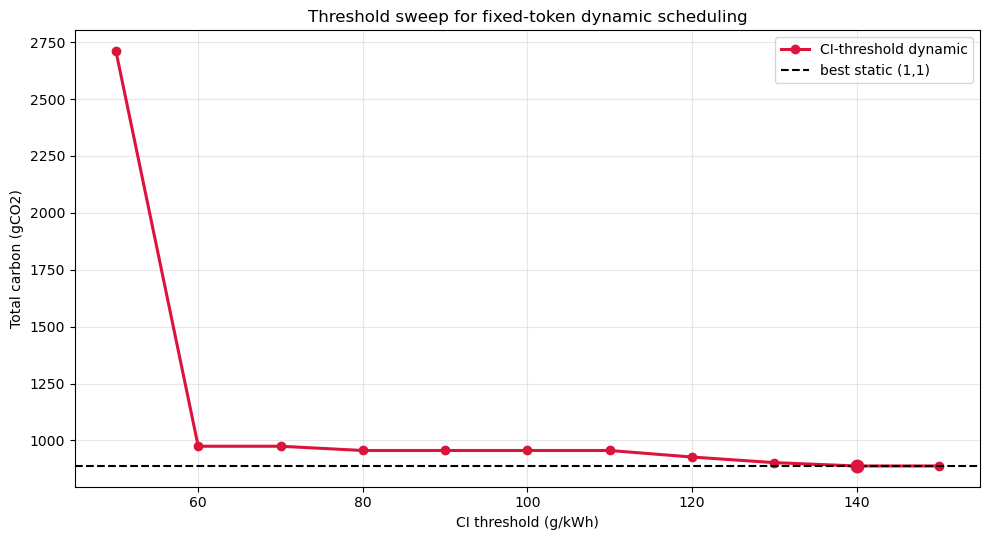

Best threshold: 140 g/kWh, 887.7 gCO2, 9.55h wall
Best static: (1,1), 887.7 gCO2, 9.55h wall


In [597]:

threshold_values = np.arange(50.0, 151.0, 10.0)
threshold_sims = [simulate_ci_threshold(strategies_by_key,
                                        HIGH_CI_KEY,
                                        LOW_CI_KEY,
                                        threshold,
                                        PRETRAINING_TOKENS,
                                        trace_t,
                                        trace_ci,
                                        TRACE_START_OFFSET_S,
                                        FRESH_BUILD_S,
                                        idle_cluster_w,
                                        CONTAINER_STARTUP_S,
                                        tokens_per_iter,
                                        RESHARD_TIME_S,
                                        FIRST_RESHARD_CACHE_MISS_S)
                  for threshold in threshold_values]

threshold_carbons = np.array([sim['total_carbon_g'] for sim in threshold_sims])
best_idx = int(np.argmin(threshold_carbons))
best_threshold = threshold_values[best_idx]
best_sweep_sim = threshold_sims[best_idx]
static_best = min(carbon_sims, key=lambda sim: sim['total_carbon_g'])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(threshold_values, threshold_carbons, color='crimson', linewidth=2.2, marker='o',
        label='CI-threshold dynamic')
ax.axhline(static_best['total_carbon_g'], color='black', linestyle='--', linewidth=1.5,
           label=f"best static ({static_best['tp']},{static_best['pp']})")
ax.plot(best_threshold, best_sweep_sim['total_carbon_g'], 'o', color='crimson', markersize=9)
ax.set_xlabel('CI threshold (g/kWh)')
ax.set_ylabel('Total carbon (gCO2)')
ax.set_title('Threshold sweep for fixed-token dynamic scheduling')
ax.grid(True, alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

print(f'Best threshold: {best_threshold:.0f} g/kWh, '
      f'{best_sweep_sim["total_carbon_g"]:.1f} gCO2, '
      f'{best_sweep_sim["duration_s"] / 3600.0:.2f}h wall')
print(f"Best static: ({static_best['tp']},{static_best['pp']}), "
      f"{static_best['total_carbon_g']:.1f} gCO2, "
      f"{static_best['duration_s'] / 3600.0:.2f}h wall")
